# 05 · Exactitud, pruebas de validación y ajustes del modelo

**Pregunta:** ¿qué exactitud tiene el modelo de segmentación, cómo se validó y qué ajustes se hicieron?

En un problema **supervisado** (por ejemplo, predecir si un cliente vuelve a comprar) la exactitud compara la predicción
con una etiqueta real. La segmentación es **no supervisada**: no existe un «segmento verdadero» de cada cliente con el que
comparar, así que la exactitud no se puede calcular directamente sobre los clusters. Lo que sí se puede medir, con datos de
**entrenamiento** y de **prueba** separados, es:

1. **Exactitud de reasignación.** Se entrena todo el proceso (preprocesado + K-Means) sin un grupo de clientes y después se
   asigna segmento a esos clientes, que el modelo no vio. Se compara con el segmento que tienen en el modelo final. Es
   exactamente lo que hace la app con un cliente nuevo.
2. **Exactitud de clasificadores supervisados.** Se toman los segmentos como etiqueta y se entrenan clasificadores
   (árbol de decisión y bosque aleatorio) con el 80 % de los clientes. Su exactitud en el 20 % restante mide si los
   segmentos son **reproducibles y explicables** con reglas sencillas sobre las cuatro variables.

Además se resumen las pruebas de validación interna del notebook 03 y la tabla de **ajustes** (hiperparámetros probados y
elegidos) de todo el proyecto.

In [1]:
import json
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text

from segmentacion import config
from segmentacion.catalogo import SEGMENTOS
from segmentacion.evaluacion import comparar_clasificadores, exactitud_reasignacion
from segmentacion.features import VARIABLES_CLUSTERING, construir_preprocesador
from segmentacion.modelado import ajustar_kmeans
from segmentacion.prediccion import ETIQUETAS_VARIABLES
from segmentacion.visualizacion import COLOR_NEUTRO, COLOR_PRINCIPAL, COLOR_SECUNDARIO, estilo, guardar_figura

estilo()
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

clientes = pd.read_parquet(config.PARQUET_SEGMENTADOS)
metricas = json.loads(config.JSON_METRICAS.read_text(encoding="utf-8"))
features = json.loads(config.JSON_FEATURES.read_text(encoding="utf-8"))
X = clientes[VARIABLES_CLUSTERING]
y = clientes["segmento"].to_numpy()
K = metricas["modelo_final"]["k"]
NOMBRES = [SEGMENTOS[s]["nombre"] for s in range(K)]
print(f"{len(X):,} clientes · {K} segmentos · variables: {VARIABLES_CLUSTERING}")
pd.Series(y).value_counts().sort_index().rename(index=dict(enumerate(NOMBRES))).to_frame("clientes")

4,324 clientes · 4 segmentos · variables: ['recency', 'frequency', 'ticket_promedio', 'productos_distintos']


,clientes
Pequeños ocasionales,1040
Grandes ocasionales,1226
En crecimiento,1170
VIP,888


## 1. Pruebas de validación ya hechas (notebook 03)

Sin etiqueta real, un clustering se valida con tres tipos de prueba: **métricas internas** (compacidad y separación),
**estabilidad** (¿sale lo mismo con otros datos?) y **robustez** (¿cambia si se alteran los datos de forma razonable?).

In [2]:
final = metricas["modelo_final"]
validacion_interna = pd.DataFrame([
    ("Silhouette (−1 a 1, ↑ mejor)", final["silhouette"], "Cohesión y separación de los clusters"),
    ("Davies-Bouldin (↓ mejor)", final["davies_bouldin"], "Parecido medio de cada cluster con el más cercano"),
    ("Calinski-Harabasz (↑ mejor)", final["calinski_harabasz"], "Dispersión entre clusters frente a dentro de ellos"),
    ("Estabilidad: ARI mediano (50 submuestras del 80 %)", final["estabilidad_mediana"], "1 = misma partición siempre"),
    ("Estabilidad: ARI en el peor 10 % de submuestras", final["estabilidad_p10"], "Estabilidad en el peor caso"),
    ("Robustez a empates de frecuencia (ARI)", final["ARI_descuantizado"], "Frecuencia «descuantizada» al azar"),
], columns=["prueba", "valor", "qué mide"])
validacion_interna

,prueba,valor,qué mide
0,"Silhouette (−1 a 1, ↑ mejor)",0.2402,Cohesión y separación de los clusters
1,Davies-Bouldin (↓ mejor),1.2823,Parecido medio de cada cluster con el más cercano
2,Calinski-Harabasz (↑ mejor),"1,926.4031",Dispersión entre clusters frente a dentro de e...
3,Estabilidad: ARI mediano (50 submuestras del 8...,0.9585,1 = misma partición siempre
4,Estabilidad: ARI en el peor 10 % de submuestras,0.9291,Estabilidad en el peor caso
5,Robustez a empates de frecuencia (ARI),0.9415,Frecuencia «descuantizada» al azar


**Hallazgos — validación interna**

- El silhouette (0,240) es moderado: los clientes forman una nube continua y los segmentos son cortes de esa nube, no
  grupos aislados (se discute en el notebook 03).
- La partición es **muy estable**: con 50 submuestras del 80 % el ARI mediano es 0,958 y en el peor 10 % de las
  submuestras sigue en 0,929. También resiste el reparto aleatorio de los empates de frecuencia (ARI 0,941).
- Estas pruebas dicen que los segmentos son consistentes, pero no dan un porcentaje de «acierto». Para eso están las dos
  pruebas siguientes.

## 2. Prueba 1 · Exactitud de reasignación (entrenamiento / prueba, 5 pliegues)

Validación cruzada estratificada de 5 pliegues: en cada uno se reentrena el **pipeline completo** (log1p, límites de
winsorizado p1–p99, escalado y K-Means con k = 4) solo con el 80 % de los clientes, y se asigna segmento al 20 % restante.
Como los números de cluster son arbitrarios, antes de comparar se alinean con el algoritmo húngaro. Cada cliente queda
una vez en el conjunto de prueba.

In [3]:
def entrenar_segmentacion(entrenamiento: pd.DataFrame):
    preprocesador = construir_preprocesador(entrenamiento)
    modelo = ajustar_kmeans(preprocesador.transform(entrenamiento), K)
    return lambda nuevos: modelo.predict(preprocesador.transform(nuevos))


reasignacion = exactitud_reasignacion(X, y, entrenar_segmentacion, n_pliegues=5)
print(f"Exactitud media: {reasignacion['exactitud'].mean():.4f} · mínima: {reasignacion['exactitud'].min():.4f} · "
      f"máxima: {reasignacion['exactitud'].max():.4f}")
reasignacion

Exactitud media: 0.9817 · mínima: 0.9676 · máxima: 0.9931


,pliegue,n_entrenamiento,n_prueba,exactitud
0,1,3459,865,0.9861
1,2,3459,865,0.9734
2,3,3459,865,0.9884
3,4,3459,865,0.9931
4,5,3460,864,0.9676


**Hallazgos — exactitud de reasignación**

- Entrenado sin ver a los clientes de prueba, el modelo les asigna **el mismo segmento que el modelo final en el 98,2 %
  de los casos** (media de 5 pliegues; entre 96,8 % y 99,3 %).
- Es la prueba más directa de lo que hace la app: clasificar a un cliente nuevo con un modelo que no lo conocía. El 1,8 %
  restante son clientes en la frontera entre dos segmentos vecinos, donde un pequeño cambio en los centroides los pasa
  al otro lado.

## 3. Prueba 2 · Clasificadores supervisados que aprenden los segmentos

**Partición:** 80 % entrenamiento / 20 % prueba, estratificada por segmento y con `random_state = 42`. El conjunto de
prueba **no se usa** para elegir nada: los ajustes se eligen con validación cruzada de 5 pliegues dentro del entrenamiento.

Los clasificadores usan las cuatro variables **en su escala original** (días, facturas, libras, productos): un árbol de
decisión no cambia con transformaciones monótonas como log1p, y así sus reglas se leen en unidades de negocio.

In [4]:
X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.2, stratify=y, random_state=config.RANDOM_STATE)
print(f"Entrenamiento: {len(X_ent):,} clientes · prueba: {len(X_pru):,} clientes")

Entrenamiento: 3,459 clientes · prueba: 865 clientes


### 3.1 Ajuste de hiperparámetros del árbol (búsqueda en rejilla)

Se prueban todas las combinaciones de **profundidad máxima** y **mínimo de clientes por hoja** y se elige la de mayor
exactitud media en validación cruzada (`GridSearchCV`).

In [5]:
pliegues = StratifiedKFold(n_splits=5, shuffle=True, random_state=config.RANDOM_STATE)
REJILLA = {"max_depth": [2, 3, 4, 5, 6, 8, 10, 12, None], "min_samples_leaf": [1, 5, 10, 20]}
busqueda = GridSearchCV(DecisionTreeClassifier(random_state=config.RANDOM_STATE), REJILLA, cv=pliegues,
                        scoring="accuracy", return_train_score=True).fit(X_ent, y_ent)
MEJORES = busqueda.best_params_
print(f"Combinaciones probadas: {len(busqueda.cv_results_['params'])} · mejor: {MEJORES} · "
      f"exactitud CV: {busqueda.best_score_:.4f}")

resultados = pd.DataFrame(busqueda.cv_results_)
resultados["profundidad"] = resultados["param_max_depth"].map(lambda d: "sin límite" if d is None else str(int(d)))
curva = (resultados.sort_values("mean_test_score", ascending=False).groupby("profundidad", sort=False).head(1)
         .set_index("profundidad").loc[[str(d) for d in REJILLA["max_depth"] if d] + ["sin límite"]]
         [["mean_train_score", "mean_test_score", "param_min_samples_leaf"]]
         .rename(columns={"mean_train_score": "exactitud_entrenamiento", "mean_test_score": "exactitud_cv",
                          "param_min_samples_leaf": "min_hoja"}))
curva

Combinaciones probadas: 36 · mejor: {'max_depth': 10, 'min_samples_leaf': 1} · exactitud CV: 0.9159


,exactitud_entrenamiento,exactitud_cv,min_hoja
profundidad,,,
2,0.6654,0.6571,20
3,0.8090,0.7942,20
4,0.8620,0.8384,5
5,0.9104,0.8774,5
6,0.9318,0.8870,5
8,0.9772,0.9098,1
10,0.9967,0.9159,1
12,0.9996,0.9150,1
sin límite,1.0000,0.9156,1


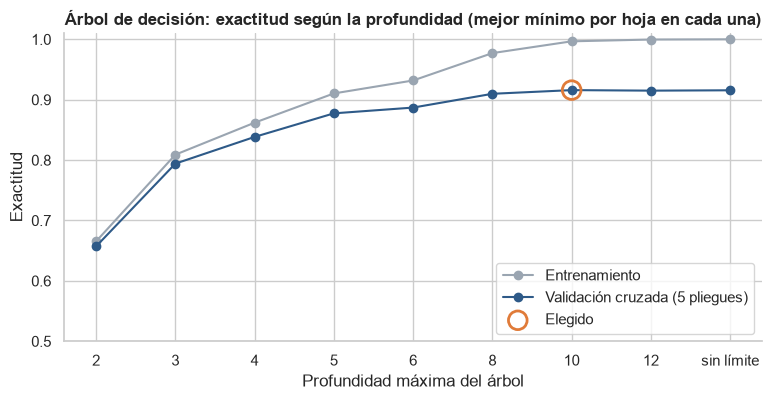

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(curva.index, curva["exactitud_entrenamiento"], marker="o", color=COLOR_NEUTRO, label="Entrenamiento")
ax.plot(curva.index, curva["exactitud_cv"], marker="o", color=COLOR_PRINCIPAL, label="Validación cruzada (5 pliegues)")
mejor = "sin límite" if MEJORES["max_depth"] is None else str(MEJORES["max_depth"])
ax.scatter([mejor], [curva.loc[mejor, "exactitud_cv"]], s=180, facecolors="none", edgecolors=COLOR_SECUNDARIO,
           linewidths=2, zorder=3, label="Elegido")
ax.set(xlabel="Profundidad máxima del árbol", ylabel="Exactitud", ylim=(0.5, 1.01),
       title="Árbol de decisión: exactitud según la profundidad (mejor mínimo por hoja en cada una)")
ax.legend(loc="lower right")
guardar_figura(fig, "05_exactitud_profundidad")
plt.show()

**Hallazgos — ajuste del árbol**

- Se probaron 36 combinaciones. La mejor es **profundidad 10 con mínimo 1 cliente por hoja** (exactitud en validación
  cruzada 91,6 %).
- La curva muestra el compromiso entre sencillez y exactitud: con profundidad 3 el árbol acierta el 79,4 %, con 5 el
  87,7 % y a partir de 8 la exactitud de validación se estanca en torno al 91 %.
- Más profundidad solo mejora la exactitud de **entrenamiento** (llega al 100 % sin límite) mientras la de validación no
  sube: es sobreajuste. Por eso el criterio de elección es la validación cruzada y no el entrenamiento.

### 3.2 Exactitud en el conjunto de prueba

Se comparan tres clasificadores, todos con la misma partición:

- **Árbol de profundidad 3**: el más sencillo de leer (como mucho 8 reglas).
- **Árbol ajustado**: los hiperparámetros elegidos en la rejilla.
- **Bosque aleatorio** (300 árboles, parámetros por defecto): referencia de un modelo más potente y menos interpretable.

In [7]:
MODELOS = {
    "Árbol de decisión (profundidad 3)": DecisionTreeClassifier(max_depth=3, random_state=config.RANDOM_STATE),
    "Árbol de decisión ajustado": DecisionTreeClassifier(**MEJORES, random_state=config.RANDOM_STATE),
    "Bosque aleatorio (300 árboles)": RandomForestClassifier(n_estimators=300, random_state=config.RANDOM_STATE,
                                                             n_jobs=-1),
}
comparativa = comparar_clasificadores(MODELOS, X_ent, y_ent, X_pru, y_pru)
comparativa

,modelo,exactitud_cv,exactitud_cv_std,exactitud_prueba
0,Árbol de decisión (profundidad 3),0.7942,0.0180,0.8197
1,Árbol de decisión ajustado,0.9159,0.0149,0.9133
2,Bosque aleatorio (300 árboles),0.9526,0.0053,0.9468


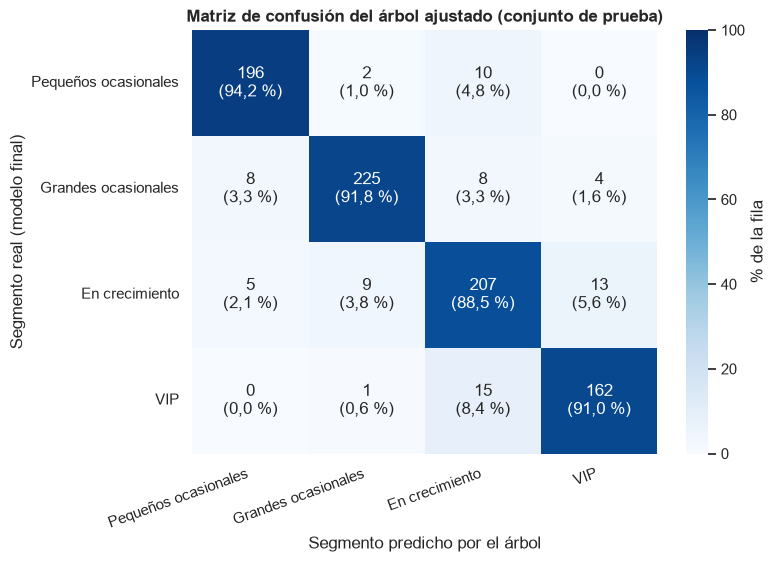

,precision,recall,f1-score,support
Pequeños ocasionales,0.9378,0.9423,0.9400,208.0000
Grandes ocasionales,0.9494,0.9184,0.9336,245.0000
En crecimiento,0.8625,0.8846,0.8734,234.0000
VIP,0.9050,0.9101,0.9076,178.0000
accuracy,0.9133,0.9133,0.9133,0.9133
macro avg,0.9137,0.9139,0.9137,865.0000
weighted avg,0.9140,0.9133,0.9135,865.0000


In [8]:
arbol = DecisionTreeClassifier(**MEJORES, random_state=config.RANDOM_STATE).fit(X_ent, y_ent)
prediccion = arbol.predict(X_pru)
matriz = confusion_matrix(y_pru, prediccion, labels=list(range(K)))
porcentaje_fila = 100 * matriz / matriz.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
anotaciones = np.array([[f"{n}\n({p:.1f} %)".replace(".", ",") for n, p in zip(fn, fp)]
                        for fn, fp in zip(matriz, porcentaje_fila)])
sns.heatmap(porcentaje_fila, annot=anotaciones, fmt="", cmap="Blues", vmin=0, vmax=100, cbar_kws={"label": "% de la fila"},
            xticklabels=NOMBRES, yticklabels=NOMBRES, ax=ax)
ax.set(xlabel="Segmento predicho por el árbol", ylabel="Segmento real (modelo final)",
       title="Matriz de confusión del árbol ajustado (conjunto de prueba)")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
guardar_figura(fig, "05_matriz_confusion")
plt.show()

reporte = pd.DataFrame(classification_report(y_pru, prediccion, labels=list(range(K)), target_names=NOMBRES,
                                             output_dict=True)).T
reporte

**Hallazgos — exactitud en el conjunto de prueba (865 clientes no usados para entrenar)**

| Clasificador | Exactitud en validación cruzada | Exactitud en prueba |
|---|---|---|
| Árbol de profundidad 3 | 79,4 % | 82,0 % |
| Árbol ajustado (profundidad 10) | 91,6 % | **91,3 %** |
| Bosque aleatorio (300 árboles) | 95,3 % | **94,7 %** |

- La exactitud en prueba es casi igual a la de validación cruzada: el modelo **no está sobreajustado** y la estimación es
  fiable.
- Los errores se concentran en **En crecimiento** (precisión 86,3 %, recall 88,5 %), el segmento intermedio que limita
  con los otros tres. De los 16 VIP mal clasificados, 15 van a En crecimiento; ningún VIP se confunde con Pequeños
  ocasionales ni al revés: los errores son entre segmentos **vecinos**, nunca entre los extremos.
- Pequeños ocasionales (F1 94,0 %) y Grandes ocasionales (F1 93,4 %) son los más fáciles de reconocer.

## 4. Las reglas del árbol de profundidad 3

El árbol más pequeño traduce los segmentos a reglas sobre las variables originales. Sirve para explicar el modelo a
negocio: «si un cliente tiene X facturas y un ticket de Y, es de tal segmento».

In [9]:
arbol_3 = DecisionTreeClassifier(max_depth=3, random_state=config.RANDOM_STATE).fit(X_ent, y_ent)
REGLAS_3 = export_text(arbol_3, feature_names=[ETIQUETAS_VARIABLES[v] for v in VARIABLES_CLUSTERING],
                       class_names=NOMBRES, decimals=1)
print(REGLAS_3)

|--- Número de facturas <= 4.5
|   |--- Ticket promedio (£) <= 264.8
|   |   |--- Productos distintos <= 23.5
|   |   |   |--- class: Pequeños ocasionales
|   |   |--- Productos distintos >  23.5
|   |   |   |--- class: En crecimiento
|   |--- Ticket promedio (£) >  264.8
|   |   |--- Días desde la última compra <= 37.5
|   |   |   |--- class: En crecimiento
|   |   |--- Días desde la última compra >  37.5
|   |   |   |--- class: Grandes ocasionales
|--- Número de facturas >  4.5
|   |--- Productos distintos <= 79.5
|   |   |--- Número de facturas <= 6.5
|   |   |   |--- class: En crecimiento
|   |   |--- Número de facturas >  6.5
|   |   |   |--- class: VIP
|   |--- Productos distintos >  79.5
|   |   |--- Días desde la última compra <= 73.5
|   |   |   |--- class: VIP
|   |   |--- Días desde la última compra >  73.5
|   |   |   |--- class: VIP



**Hallazgos — reglas del árbol de profundidad 3 (82,0 % de exactitud en prueba)**

- **Pequeños ocasionales:** hasta 4 facturas, ticket de hasta 264,8 £ y como mucho 23 productos distintos.
- **Grandes ocasionales:** hasta 4 facturas, ticket mayor de 264,8 £ y más de 37 días sin comprar.
- **VIP:** más de 6 facturas, o más de 4 facturas con más de 79 productos distintos.
- **En crecimiento:** los casos intermedios (pocas facturas pero muchos productos o compra reciente, o 5–6 facturas).
- Las reglas confirman el perfil de cada segmento: la frecuencia separa ocasionales de recurrentes y el ticket separa
  pequeños de grandes ocasionales.

## 5. Ajustes del proyecto: qué se probó y qué se eligió

Resumen de los hiperparámetros y decisiones de modelado de los notebooks 02 y 03, y del ajuste del árbol de este
notebook. Los valores salen de los artefactos guardados (`models/features.json`, `models/metricas.json`) o de este
notebook.

In [10]:
gmm, dbscan, hdbscan, tsne = metricas["gmm"], metricas["dbscan"], metricas["hdbscan"], metricas["tsne"]
tipos_gmm = sorted({fila["tipo"] for fila in gmm["rejilla_bic"]})
k_gmm = sorted({fila["k"] for fila in gmm["rejilla_bic"]})
k_kmeans = [fila["k"] for fila in metricas["barrido_kmeans"]]
p_bajo, p_alto = features["winsorizado_percentiles"]
mejor_hoja = MEJORES["min_samples_leaf"]
mejor_prof = "sin límite" if MEJORES["max_depth"] is None else MEJORES["max_depth"]


def rango(valores):
    return f"{min(valores)} a {max(valores)}"


AJUSTES = [
    ("Preprocesado", "Transformación", "sin transformar / log1p", features["transformacion"],
     "Las cuatro variables son muy asimétricas; con log1p quedan casi simétricas (comparación de asimetría, notebook 02)"),
    ("Preprocesado", "Escalado", "StandardScaler / RobustScaler", features["escalador"],
     "Todas las variables pesan igual en la distancia; RobustScaler daba más peso al ticket sin razón de negocio"),
    ("Preprocesado", "Valores extremos", "mantener / winsorizar",
     f"winsorizar p{p_bajo:g}–p{p_alto:g} (en log1p)", "Los extremos ya no arrastran los centroides de K-Means"),
    ("Preprocesado", "Variables del clustering", "4 variables + gasto total (VIF) + tasa de devoluciones",
     ", ".join(VARIABLES_CLUSTERING),
     "Gasto = facturas × ticket (redundante, VIF); la tasa de devoluciones creaba un cluster solo de devolvedores"),
    ("K-Means", "Número de clusters k", rango(k_kmeans), str(K),
     "k = 2 gana en métricas pero no es accionable; k = 4 es estable y k = 5 es inestable"),
    ("K-Means", "Inicializaciones (n_init)", "—", "10 (k-means++)", "Se queda con la mejor de 10 inicializaciones"),
    ("GMM", "Tipo de covarianza × k", f"{', '.join(tipos_gmm)} × k {rango(k_gmm)}", f"{gmm['tipo']}, k = {gmm['k']}",
     "Menor BIC"),
    ("GMM", "reg_covar", "1e-6 a 0,1 (10 valores)", f"{gmm['reg_covar']:g}".replace(".", ","),
     "Mínimo valor sin componentes degenerados por los empates de frecuencia = 1"),
    ("DBSCAN", "eps", "codo de las distancias al 8.º vecino", f"{dbscan['eps']:.3f}".replace(".", ","),
     "Punto de máxima curvatura del gráfico de k-distancias"),
    ("DBSCAN", "min_samples", "regla 2 × nº de variables", str(dbscan["min_samples"]), "Regla habitual de la literatura"),
    ("HDBSCAN", "min_cluster_size", "2 % de los clientes", str(hdbscan["min_cluster_size"]),
     "Tamaño mínimo de un segmento útil"),
    ("t-SNE", "perplexity", ", ".join(str(p) for p in tsne["perplexities_exploradas"]), str(tsne["perplexity_guardada"]),
     "Equilibrio entre estructura local y global (solo para visualizar)"),
    ("Árbol de decisión", "max_depth × min_samples_leaf",
     f"{len(REJILLA['max_depth'])} × {len(REJILLA['min_samples_leaf'])} = {len(busqueda.cv_results_['params'])} "
     "combinaciones", f"{mejor_prof} y {mejor_hoja}", "Mayor exactitud en validación cruzada de 5 pliegues"),
]
ajustes = pd.DataFrame(AJUSTES, columns=["etapa", "parámetro", "valores probados", "elegido", "criterio"])
ajustes

,etapa,parámetro,valores probados,elegido,criterio
0,Preprocesado,Transformación,sin transformar / log1p,log1p,Las cuatro variables son muy asimétricas; con ...
1,Preprocesado,Escalado,StandardScaler / RobustScaler,StandardScaler,Todas las variables pesan igual en la distanci...
2,Preprocesado,Valores extremos,mantener / winsorizar,winsorizar p1–p99 (en log1p),Los extremos ya no arrastran los centroides de...
3,Preprocesado,Variables del clustering,4 variables + gasto total (VIF) + tasa de devo...,"recency, frequency, ticket_promedio, productos...","Gasto = facturas × ticket (redundante, VIF); l..."
4,K-Means,Número de clusters k,2 a 10,4,k = 2 gana en métricas pero no es accionable; ...
5,K-Means,Inicializaciones (n_init),—,10 (k-means++),Se queda con la mejor de 10 inicializaciones
6,GMM,Tipo de covarianza × k,"diag, full, spherical, tied × k 2 a 10","full, k = 7",Menor BIC
7,GMM,reg_covar,"1e-6 a 0,1 (10 valores)","0,05",Mínimo valor sin componentes degenerados por l...
8,DBSCAN,eps,codo de las distancias al 8.º vecino,"0,717",Punto de máxima curvatura del gráfico de k-dis...
9,DBSCAN,min_samples,regla 2 × nº de variables,8,Regla habitual de la literatura


## 6. Guardar los resultados para la app y los informes

In [11]:
validacion = {
    "reasignacion": {
        "n_pliegues": len(reasignacion), "pliegues": reasignacion.to_dict(orient="records"),
        "media": float(reasignacion["exactitud"].mean()), "minimo": float(reasignacion["exactitud"].min()),
        "maximo": float(reasignacion["exactitud"].max()),
    },
    "clasificadores": {
        "proporcion_prueba": 0.2, "n_entrenamiento": len(X_ent), "n_prueba": len(X_pru), "n_pliegues_cv": 5,
        "rejilla": {"max_depth": [d if d is not None else "sin límite" for d in REJILLA["max_depth"]],
                    "min_samples_leaf": REJILLA["min_samples_leaf"]},
        "n_combinaciones": len(busqueda.cv_results_["params"]),
        "mejores_parametros": {"max_depth": MEJORES["max_depth"], "min_samples_leaf": MEJORES["min_samples_leaf"]},
        "comparativa": comparativa.to_dict(orient="records"),
        "curva_profundidad": curva.reset_index().astype({"min_hoja": int}).to_dict(orient="records"),
        "matriz_confusion": matriz.tolist(),
        "nombres": NOMBRES,
        "reporte": [{"segmento": nombre, "precision": float(reporte.loc[nombre, "precision"]),
                     "recall": float(reporte.loc[nombre, "recall"]), "f1": float(reporte.loc[nombre, "f1-score"]),
                     "soporte": int(reporte.loc[nombre, "support"])} for nombre in NOMBRES],
        "reglas_profundidad_3": REGLAS_3,
    },
    "ajustes": ajustes.to_dict(orient="records"),
}
config.JSON_VALIDACION.write_text(json.dumps(validacion, indent=2, ensure_ascii=False), encoding="utf-8")
recargado = json.loads(config.JSON_VALIDACION.read_text(encoding="utf-8"))
print("validacion.json:", list(recargado), "· exactitud reasignación:", round(recargado["reasignacion"]["media"], 4))

validacion.json: ['reasignacion', 'clasificadores', 'ajustes'] · exactitud reasignación: 0.9817


## 7. Conclusiones

- **Exactitud:** al clasificar clientes que no vio al entrenar, el modelo coincide con el segmento final en el **98,2 %**
  de los casos. Un árbol de decisión aprende los segmentos con un **91,3 %** de exactitud en prueba y un bosque
  aleatorio con un **94,7 %**.
- Estas cifras no son comparables con la exactitud de un problema supervisado (predecir una etiqueta real): aquí miden si
  los segmentos son **reproducibles** con datos nuevos y **explicables** con reglas sencillas. Junto con la estabilidad
  (ARI 0,958) muestran que la segmentación es consistente aunque el silhouette sea moderado.
- **Pruebas de validación:** métricas internas, estabilidad por submuestreo, robustez a empates, reasignación con
  validación cruzada de 5 pliegues y clasificadores con partición 80/20 y validación cruzada. Además, el código tiene
  pruebas automáticas (`pytest`) del emparejamiento de cancelaciones, las variables, el modelado, la predicción, estas
  medidas de exactitud y la app.
- **Ajustes:** la tabla del apartado 5 resume todos los hiperparámetros probados y el criterio de elección de cada uno.